# Logistic Regression, Explained Step by Step (scikit-learn)

A beginner-friendly walkthrough of **binary classification** with logistic
regression. Worked example: predicting telecom customer **churn** (will a customer
cancel?).

Every section explains:
- **What** we're doing,
- **Why** we do it,
- and **what the output means**.

It's also a **template**: to reuse it on another dataset you only change a few
"knobs" (highlighted throughout), and the rest of the notebook works as-is.

---

### The big picture (read this first)

Machine learning here is just this loop:

1. **Load data** — a table of examples (customers) with features and a known answer.
2. **Split** it — keep some data hidden so we can test honestly.
3. **Explore** it — learn which columns look useful.
4. **Preprocess** — turn text categories into numbers the model understands.
5. **Train** a model — let it find the relationship between features and the answer.
6. **Evaluate** — measure how good it is on data it has never seen.
7. **Interpret & analyze errors** — understand *why* it's right or wrong.

### Tiny glossary (terms used below)

- **Feature (X)** — an input column (e.g. `tenure`, `contract`).
- **Target / label (y)** — the thing we predict (here: churn, 0 or 1).
- **Binary classification** — predicting one of two classes.
- **Model** — a function that maps features to a prediction.
- **Training** — fitting the model's parameters to data.
- **Overfitting** — memorizing training data instead of learning general patterns.
- **Pipeline** — a bundle of preprocessing steps + model that runs together.

> **Evaluation-metrics deep dive:** section 3.13 explains *why* we use a
> confusion matrix, precision/recall, F1, and ROC-AUC — what each one answers, and
> which to pick for a given problem.



## 3.1 The problem

We want to predict whether a customer will **churn** (cancel their subscription).
This is **binary classification**: the target has two possible values, *yes* or
*no*.

We'll use **logistic regression**. In one sentence: it's a **linear model** (adds
up feature values with weights, like `y = w0 + w1*x1 + ...`) whose output is pushed
through a **sigmoid** so it becomes a **probability between 0 and 1**.

Why start here?
- It's the simplest classifier — easy to understand and explain.
- It's **interpretable**: each feature gets a weight you can read.
- It's a strong baseline before trying fancier models.

* Dataset: <https://www.kaggle.com/blastchar/telco-customer-churn>


## 3.2 Load and clean the data

**Goal:** get a clean table where
- column names are consistent,
- text values are consistent,
- numbers are actually numbers,
- the target is 0/1.

**Packages used:** `pandas` (dataframes), `numpy` (numbers/arrays),
`matplotlib` (plots).


In [1]:
# Import the libraries we'll use throughout.
import pandas as pd                       # tables / data manipulation
import numpy as np                        # numbers and arrays
import matplotlib.pyplot as plt           # plotting


/Users/raymondcancino/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/w5/07555mrj4b92zd89byxnxjnr0000gn/T/matplotlib-u1laksap because there was an issue with the default path (/Users/raymondcancino/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/raymondcancino/.cache/fontconfig
	/Users/raymondcancino/.fontconfig


Matplotlib is building the font cache; this may take a moment.


### The template knobs

These are the settings you change for a different dataset. Everything downstream
depends on them, so they live at the top for easy editing.


In [2]:
# --- TEMPLATE KNOBS (change these for a new dataset) ---
DATA_PATH = '../data/telco.csv'   # where the CSV lives
TARGET = 'churn'                  # the column we want to predict
POSITIVE_LABEL = 'yes'            # the value of TARGET that means "yes"


### Load and look

`read_csv` reads the file into a **DataFrame** (a table). `head()` shows the first
5 rows so we can see what we're working with.


In [3]:
# Read the CSV file into a table (DataFrame)
df = pd.read_csv(DATA_PATH)

# Show the first 5 rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Clean column names and text values

Data from the wild is messy: `'MonthlyCharges'`, `'monthly charges'`,
`'monthlycharges'` are all the same concept but different strings. Standardizing
(lowercasing, replacing spaces with underscores) avoids annoying bugs later.

We only apply the text transform to columns that contain text (`object`/`string`),
never to numbers.


In [4]:
# Column names: lowercase + spaces -> underscores
# e.g. 'MonthlyCharges' -> 'monthlycharges'
df.columns = df.columns.str.lower().str.replace(' ', '_')

# Text *values*: lowercase + spaces -> underscores
# e.g. 'Fiber optic' -> 'fiber_optic', 'Yes' -> 'yes'
# We use select_dtypes to touch only text columns.
for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')


### Make sure numbers are numbers

Sometimes a column that should be numeric is read as text because a few cells are
blank or have stray spaces. `totalcharges` is a classic example.

Our fix: try to convert each text column to numbers. If **almost all** values
convert cleanly (>95%), keep the numeric version (filling blanks with 0). This is
a small heuristic that makes the notebook reusable; in a real project you'd inspect
those blanks deliberately.


In [5]:
# Try to convert any text column to numbers; keep it if it mostly parses.
for c in df.columns:
    # is_string_dtype covers both pandas 2 ('object') and pandas 3 ('str');
    # comparing dtype names directly is fragile across versions.
    if pd.api.types.is_string_dtype(df[c]):
        converted = pd.to_numeric(df[c], errors='coerce')  # blanks -> NaN
        if converted.notna().mean() > 0.95:                # >95% parsed as numbers
            df[c] = converted.fillna(0)                    # keep numeric, fill blanks


### Encode the target as 0/1

Models do math, so the answer column must be numeric. We map `'yes'` -> `1` and
everything else -> `0`. `astype(int)` converts the booleans (`True`/`False`) to
`1`/`0`.


In [6]:
# Turn the target into 0/1: 1 where it equals POSITIVE_LABEL, else 0
df[TARGET] = (df[TARGET] == POSITIVE_LABEL).astype(int)

# Peek at the result
df[TARGET].head()


0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

## 3.3 Split into train / validation / test

**Why split?** If we measure the model on the same data it learned from, it looks
better than it really is (it could just memorize). So we hold data out.

We make **three** sets:

| Set | Size | Purpose |
|---|---|---|
| **train** | 60% | the model learns from this |
| **validation** | 20% | we use it to *make choices* (check the model) |
| **test** | 20% | used **once at the very end** for an honest score |

Think of it like school: train = homework, validation = practice quizzes, test =
the final exam (you don't get to see it beforehand).

**How we get 60/20/20:** call `train_test_split` twice.
1. Carve off 20% as **test** (the remaining 80% is "train + val").
2. Carve off 25% of that 80% as **validation** (25% x 80% = 20% overall).
What's left = 60% **train**.

**Package:** `sklearn.model_selection.train_test_split`.


In [7]:
from sklearn.model_selection import train_test_split

# Split 1: hold out 20% for the final test set.
# random_state=1 makes the split reproducible (same split every run).
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

# Split 2: hold out 25% of the remaining 80% for validation.
# 25% of 80% = 20% of the original -> train is the final 60%.
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Confirm the sizes (notice they're roughly 60 / 20 / 20)
len(df_train), len(df_val), len(df_test)


(4225, 1409, 1409)

### Separate the features (X) from the target (y)

- **X** = the input columns the model uses.
- **y** = the answer it should predict.

We must extract `y` **before** dropping the target column from X — otherwise we'd
lose it. Keeping the target out of X is important: if we accidentally left it in,
the model would "cheat" by seeing the answer (this mistake is called **leakage**).


In [8]:
# Re-number the rows 0..n-1 in each set (clean, predictable indexes)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# y = the target values, pulled out as numpy arrays
y_train = df_train[TARGET].values
y_val = df_val[TARGET].values
y_test = df_test[TARGET].values
y_full_train = df_full_train[TARGET].values

# X = all the feature columns = everything EXCEPT the target
df_train = df_train.drop(columns=[TARGET])
df_val = df_val.drop(columns=[TARGET])
df_test = df_test.drop(columns=[TARGET])


## 3.4 Summarize the data

Before modeling, **look** at the data. This quick profile answers: how big is it,
what types, any missing values, any duplicates, how balanced is the target, and
what ranges do features have?

We profile **train + validation** (`df_full_train`) only — never the test set.

**Package:** `pandas`.


### The feature-list knobs

We tell the notebook which columns are **numeric** and which are **categorical**.
This matters because they get preprocessed differently (3.8). List every feature
column here (everything except an id column and the target).


In [9]:
# --- TEMPLATE KNOBS: your feature lists ---
# Numeric columns: real numbers (age, price, counts, ...)
numerical = ['tenure', 'monthlycharges', 'totalcharges']

# Categorical columns: labels/categories (yes/no, plan type, ...)
categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice',
    'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup',
    'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies',
    'contract', 'paperlessbilling', 'paymentmethod',
]


### Shape, types, missing values

- `info()` → number of rows, column names, data types, and how many non-null values
  each column has.
- `.isnull().sum().sum()` → total count of missing cells.
- `.duplicated().sum()` → how many rows are exact duplicates of another row.


In [10]:
# Overview: rows, columns, types, non-null counts
df_full_train.info()


<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   seniorcitizen     5634 non-null   int64  
 3   partner           5634 non-null   str    
 4   dependents        5634 non-null   str    
 5   tenure            5634 non-null   int64  
 6   phoneservice      5634 non-null   str    
 7   multiplelines     5634 non-null   str    
 8   internetservice   5634 non-null   str    
 9   onlinesecurity    5634 non-null   str    
 10  onlinebackup      5634 non-null   str    
 11  deviceprotection  5634 non-null   str    
 12  techsupport       5634 non-null   str    
 13  streamingtv       5634 non-null   str    
 14  streamingmovies   5634 non-null   str    
 15  contract          5634 non-null   str    
 16  paperlessbilling  5634 non-null   str    
 17  paymen

In [11]:
# Any missing values, and any exact duplicate rows?
print('missing values:', df_full_train.isnull().sum().sum())
print('duplicate rows:', df_full_train.duplicated().sum())


missing values: 0
duplicate rows: 0


### Class balance (how common is the positive class?)

For a 0/1 target, the **mean equals the fraction of 1s**. This tells us the **churn
rate**. If the classes are very imbalanced (e.g. 95% / 5%), accuracy becomes
misleading — we'll come back to this in 3.13.


In [12]:
# Fraction of each class (0 vs 1)
df_full_train[TARGET].value_counts(normalize=True)


churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

### Numeric ranges

`describe()` gives count, mean, standard deviation, min, the quartiles (25/50/75%),
and max for each numeric column.

Notice the **scales differ a lot** (e.g. `totalcharges` in the thousands vs `tenure`
in the tens). This is exactly why we'll **scale** numeric features in 3.8.


In [13]:
# Summary statistics for numeric features
df_full_train[numerical].describe().round(2)


,tenure,monthlycharges,totalcharges
count,5634.00,5634.00,5634.00
mean,32.28,64.78,2277.42
std,24.56,30.10,2266.41
min,0.00,18.25,0.00
25%,9.00,35.40,389.14
50%,29.00,70.38,1391.00
75%,55.00,89.85,3787.50
max,72.00,118.65,8684.80


### Categorical summary

Instead of printing 16 separate tables, one compact table: how many categories each
column has, plus its most common value and that value's share. This flags columns
that are skewed (dominated by one value) or have many categories.


In [14]:
# One line per categorical column: #categories, most common value, its share
pd.DataFrame({
    'n_categories': df_full_train[categorical].nunique(),
    'top_value':    [df_full_train[c].value_counts().idxmax() for c in categorical],
    'top_share':    [round(df_full_train[c].value_counts(normalize=True).max(), 3)
                     for c in categorical],
})


,n_categories,top_value,top_share
gender,2,male,0.504
seniorcitizen,2,0,0.838
partner,2,no,0.520
dependents,2,no,0.704
phoneservice,2,yes,0.903
multiplelines,3,no,0.479
internetservice,3,fiber_optic,0.440
onlinesecurity,3,no,0.497
onlinebackup,3,no,0.443
deviceprotection,3,no,0.439


## 3.5 Feature importance #1: churn rate & risk ratio

**Feature importance** = which columns carry the most signal about the target.
We'll look at it three ways (3.5, 3.6, 3.7).

**Method 1: compare each group's churn rate to the overall ("global") rate.**

- **Difference** = `group_rate - global_rate`
  - `> 0` → this group churns **more** than average.
  - `< 0` → this group churns **less** than average.
- **Risk ratio** = `group_rate / global_rate`
  - `> 1` → churns **more** often than average.
  - `< 1` → churns **less** often than average.

The bigger the difference (or the further the ratio is from 1), the more important
the feature is.

**Package:** `pandas` (`groupby` — split the table into groups and compute per-group
statistics).


In [15]:
# The overall churn rate = our baseline to compare every group against
global_rate = df_full_train[TARGET].mean()
global_rate


np.float64(0.26996805111821087)

Worked example: does having a **partner** relate to churn? We group by `partner`
and compute the churn rate, size, difference and risk for each group.
`agg(['mean', 'count'])` computes the average (= churn rate) and the count per
group.


In [16]:
# Group by one feature and compute rate + size + diff + risk
g = df_full_train.groupby('partner')[TARGET].agg(['mean', 'count'])
g['diff'] = g['mean'] - global_rate     # how far above/below average
g['risk'] = g['mean'] / global_rate     # how many times the average
g.round(3)


,mean,count,diff,risk
partner,,,,
no,0.330,2932,0.060,1.222
yes,0.205,2702,-0.065,0.759


Now the same idea for **every** categorical feature in a loop. Read each table the
same way: groups with `risk` far from 1.0 (and large `diff` in absolute value) are
the interesting ones.


In [17]:
# Same table for every categorical feature
for c in categorical:
    g = df_full_train.groupby(c)[TARGET].agg(['mean', 'count'])
    g['diff'] = g['mean'] - global_rate
    g['risk'] = g['mean'] / global_rate
    print(c)
    print(g.round(3))
    print()


gender
         mean  count   diff   risk
gender                            
female  0.277   2796  0.007  1.025
male    0.263   2838 -0.007  0.975

seniorcitizen
                mean  count   diff   risk
seniorcitizen                            
0              0.242   4722 -0.028  0.897
1              0.413    912  0.143  1.531

partner
          mean  count   diff   risk
partner                            
no       0.330   2932  0.060  1.222
yes      0.205   2702 -0.065  0.759

dependents
             mean  count   diff   risk
dependents                            
no          0.314   3968  0.044  1.162
yes         0.166   1666 -0.104  0.614

phoneservice
               mean  count   diff   risk
phoneservice                            
no            0.241    547 -0.029  0.894
yes           0.273   5087  0.003  1.011

multiplelines
                   mean  count   diff   risk
multiplelines                               
no                0.257   2700 -0.013  0.953
no_phone_service  0.2

## 3.6 Feature importance #2: mutual information

**Mutual information** (from information theory) measures how much one variable
tells us about another. Here: how much does each **categorical** feature reduce our
uncertainty about the target?

- **0** = the feature tells us nothing about the target.
- **Higher** = more informative.

Unlike the risk-ratio method, one number summarizes the whole column at once.

**Packages:** `sklearn.metrics.mutual_info_score`, plus `pandas.apply` (run a
function down each column).


In [18]:
from sklearn.metrics import mutual_info_score

# For every categorical column, compute mutual information with the target,
# then sort so the most informative features are on top.
df_full_train[categorical].apply(
    lambda column: mutual_info_score(column, df_full_train[TARGET])
).sort_values(ascending=False)


contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

## 3.7 Feature importance #3: correlation (numeric features)

For **numeric** features, the natural measure is **correlation** with the target:
a number from -1 to +1 describing a straight-line relationship.

- **+1** = perfect positive relationship (feature up → target up).
- **-1** = perfect negative relationship (feature up → target down).
- **0** = no straight-line relationship.

We take the **absolute value** (`.abs()`) because we care about *strength*, not
direction.

**Package:** `pandas` (`.corrwith`).


In [19]:
# |correlation| of each numeric feature with the target, strongest first
df_full_train[numerical].corrwith(df_full_train[TARGET]).abs().sort_values(ascending=False)


tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

## 3.8 Preprocess: one-hot encode + scale (in a Pipeline)

Models do math, so **every feature must be numeric**. Two problems to solve:

**Problem 1 — categorical columns are text.** We use **one-hot encoding**: turn a
column with *k* categories into *k* new 0/1 columns, one per category. Example:

| contract | → | contract_month-to-month | contract_one_year | contract_two_year |
|---|---|---|---|---|
| month-to-month | | 1 | 0 | 0 |
| one_year | | 0 | 1 | 0 |

Only one column is "on" (1) per row.

**Problem 2 — numeric columns have different scales.** `totalcharges` (~thousands)
vs `tenure` (~tens). Big differences in scale can slow or destabilize the model's
optimizer, so we **standardize** each numeric column to mean 0 and standard
deviation 1 (`StandardScaler`).

We bundle all of this with scikit-learn tools:

- **`ColumnTransformer`** — send categorical columns to one step and numeric columns
  to another.
- **`OneHotEncoder(handle_unknown='ignore')`** — do the one-hot encoding.
  `handle_unknown='ignore'` means a category we didn't see during training becomes
  all-zeros at prediction time **instead of crashing** — important for real data.
- **`StandardScaler`** — standardize the numbers.

**Packages:** `sklearn.compose`, `sklearn.preprocessing`.


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# A recipe that preprocesses columns depending on their type:
#   'cat' step -> one-hot encode the categorical columns
#   'num' step -> standardize the numeric columns
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('num', StandardScaler(), numerical),
])


## 3.9 Build and train the model

### What logistic regression is

It's a **linear model**: multiply each feature by a weight, add them up, add a bias:

    z = w0 + w1*x1 + w2*x2 + ... + wn*xn

That raw score `z` can be any number, so we pass it through the **sigmoid**
function, which squashes it into the range (0, 1) — a probability:

    sigmoid(z) = 1 / (1 + exp(-z))

- `z` very negative → probability near **0**.
- `z` very positive → probability near **1**.
- `z = 0` → probability **0.5**.

**Package:** `numpy`, `matplotlib` (to draw it), `sklearn.linear_model` (the model).


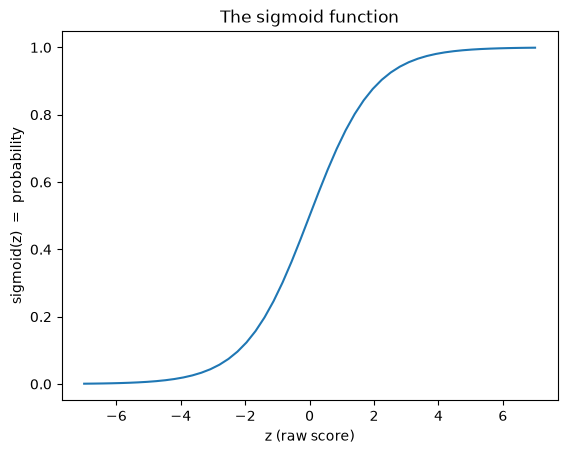

In [21]:
# The sigmoid function: turns any number into a probability in (0, 1)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Draw it to build intuition
z = np.linspace(-7, 7, 51)     # 51 points from -7 to 7
plt.plot(z, sigmoid(z))
plt.xlabel('z (raw score)')
plt.ylabel('sigmoid(z)  =  probability')
plt.title('The sigmoid function')
plt.show()


### Put it all together in a Pipeline

A **`Pipeline`** chains the preprocessing recipe and the model into one object.
Why this is great:
- You call `.fit()` once and it runs preprocessing + training in order.
- Later, `.predict()` automatically applies the **same** preprocessing that was
  learned on the training data — no risk of forgetting a step.

`max_iter=1000` gives the optimizer enough tries to converge (the default 100 is
often too few for this data and prints a warning).


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Chain: preprocessing first, then the logistic-regression model.
model = Pipeline([
    ('preprocess', preprocess),
    ('model', LogisticRegression(solver='lbfgs', max_iter=1000)),
])

# Fit = learn from the training data (features X and answers y)
model.fit(df_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['customerid','gender','seniorcitizen',...,'paymentmethod', 'monthlycharges','totalcharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

## 3.10 Evaluate on the validation set

`.predict_proba(X)` returns a probability for each class — column 0 is P(class 0),
column 1 is P(class 1). We grab column 1 with `[:, 1]` (all rows, second column).

Then we turn probabilities into hard 0/1 decisions using a **threshold** of 0.5:
"if the predicted probability of churn is at least 50%, predict churn."

**Accuracy** = fraction of predictions that match the truth.

**Package:** `sklearn` (fitted pipeline).


In [23]:
# Predicted probability of the positive class (churn=1) for each validation row
y_pred = model.predict_proba(df_val)[:, 1]

# Apply the 0.5 threshold -> 0/1 decisions
churn_decision = (y_pred >= 0.5)

# Accuracy = share of rows we got right
accuracy = (y_val == churn_decision).mean()
accuracy


np.float64(0.8062455642299503)

## 3.11 Interpret the model: which features matter?

Each encoded feature has a learned **weight** (coefficient):

- **Positive** weight → pushes the prediction toward the **positive** class (churn).
- **Negative** weight → pushes it toward the **negative** class (stay).
- **Larger magnitude** → stronger effect.

To line weights up with names we must recover the feature names **in the same
order** the encoder produced them. The categorical columns come first
(one-hot encoded), then the numeric columns.

**Package:** `sklearn` (a fitted `Pipeline` stores each step under `.named_steps`).


In [24]:
# Reach into the fitted pipeline to get the fitted one-hot encoder
encoder = model.named_steps['preprocess'].named_transformers_['cat']

# Feature names, in the exact order the model sees them:
#   first the one-hot categorical names, then the numeric names
feature_names = list(encoder.get_feature_names_out(categorical)) + numerical

# Pair each name with its weight, sorted most-positive first
coefs = pd.Series(model.named_steps['model'].coef_[0], index=feature_names)
coefs.sort_values(ascending=False).round(3)


totalcharges                               0.795
contract_month-to-month                    0.586
internetservice_fiber_optic                0.273
onlinesecurity_no                          0.180
techsupport_no                             0.131
monthlycharges                             0.130
multiplelines_no_phone_service             0.081
phoneservice_no                            0.081
paperlessbilling_yes                       0.055
paymentmethod_electronic_check             0.036
streamingmovies_yes                        0.030
onlinebackup_no                            0.011
deviceprotection_no                        0.009
streamingtv_yes                           -0.009
seniorcitizen_1                           -0.029
multiplelines_yes                         -0.046
partner_yes                               -0.063
contract_one_year                         -0.070
paymentmethod_mailed_check                -0.079
paymentmethod_credit_card_(automatic)     -0.080
dependents_no       

## 3.12 Final model + evaluation on the test set

We've now seen validation results and used them to sanity-check our approach. For
the final model we **refit on train + validation combined** — more data usually
means a better model — and then evaluate **once** on the **test set**, which has
been untouched until now.

That test score is our most honest estimate of how the model would do in the real
world.

**Package:** `sklearn.pipeline.Pipeline`, `sklearn.linear_model.LogisticRegression`.


In [25]:
# Combine train + validation features and labels
X_full_train = df_full_train[categorical + numerical]

# Same architecture as before, refit on the larger dataset
model_full = Pipeline([
    ('preprocess', preprocess),
    ('model', LogisticRegression(solver='lbfgs', max_iter=1000)),
])
model_full.fit(X_full_train, y_full_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','seniorcitizen','partner',...,'tenure','monthlycharges', 'totalcharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough

In [26]:
# Predict probabilities on the untouched test set
y_pred_test = model_full.predict_proba(df_test[categorical + numerical])[:, 1]

# Turn probabilities into 0/1 decisions with the 0.5 cutoff,
# then compare them with the true labels: accuracy = share we got right.
test_decision = (y_pred_test >= 0.5)
test_accuracy = (test_decision == y_test).mean()
test_accuracy


np.float64(0.8119233498935415)

## 3.13 Error analysis

**A note on terminology.** In *regression* (predicting a number) people talk about
**residuals** = `actual - predicted`. In *classification* the target is a category,
so there are no numeric residuals. The equivalent is **error analysis**: where and
how the model gets things wrong.

We do this on the **test set** (data the model has never seen).

**Packages:** `sklearn.metrics`, `pandas`, `matplotlib`.

### The confusion matrix

Every prediction falls into one of four buckets:

|                | predicted **no** | predicted **yes** |
|----------------|------------------|-------------------|
| **actual no**  | True Negative (TN) ✓ | False Positive (FP) — "false alarm" |
| **actual yes** | False Negative (FN) — "missed churn" | True Positive (TP) ✓ |

**Package:** `sklearn.metrics.confusion_matrix`.


### Why we need more than one metric

Imagine four teams reporting "97% accurate!" spam filters. They sound identical —
until you learn:

- One dataset is **50% spam / 50% ham** (balanced).
- One is **1% spam / 99% ham** (heavily imbalanced).

On the second dataset, "always predict ham" scores 99% — *better* than the fancy
filter — while catching **zero** spam. So the single number "accuracy" hid the fact
that the model was useless.

The lesson: **the right metric depends on the problem**. There is no single
"best" number; each metric answers a different question. This section builds up the
whole toolbox and explains *when* each one is the right choice.


### The 2x2 confusion matrix: the source of everything

Every binary prediction lands in one of four boxes. This table is where *all* the
classification metrics come from — learn it once and the metrics are just ratios of
its cells.

| | predicted **no** (0) | predicted **yes** (1) |
|---|---|---|
| **actual no** (0) | **True Negative (TN)** — correctly said no | **False Positive (FP)** — false alarm |
| **actual yes** (1) | **False Negative (FN)** — missed it | **True Positive (TP)** — correctly said yes |

Read the names carefully: **True/False** = was the *prediction* right; **Positive/
Negative** = *what we predicted*. So a **False Negative** is "we predicted
negative, and we were wrong."

**Why it matters:** the two error types usually have very different costs:

- In **cancer screening**, a False Negative (missing a cancer) can be fatal, while a
  False Positive (a scare that turns out fine) only causes an extra test. -> avoid
  FN at all costs.
- In **spam filtering**, a False Positive (a real email sent to spam) can be worse
  than a False Negative (an occasional spam in your inbox). -> avoid FP.
- In **churn prediction**, a False Negative (a customer leaves without us trying to
  save them) usually costs more than a False Positive (we offer a discount to
  someone who'd have stayed). -> lean toward catching churners.

The confusion matrix forces us to *see* both error types, so we can decide which one
to minimize.


### The metric cheat-sheet (what each one answers)

| Metric | Question it answers | Formula | Use it when |
|---|---|---|---|
| **Accuracy** | Overall, how often are we right? | `(TP+TN) / all` | Classes are balanced; every mistake costs the same |
| **Precision** | When we say "yes", how often are we right? | `TP / (TP+FP)` | False positives are expensive (spam filters) |
| **Recall** (sensitivity) | Of the real "yes", how many did we catch? | `TP / (TP+FN)` | False negatives are expensive (disease, fraud, churn) |
| **F1** | Balance of precision & recall in one number | harmonic mean of the two | You need a single number and both errors matter |
| **ROC-AUC** | How well does the model *rank* positives above negatives, across all thresholds? | area under the ROC curve | You care about ranking / comparing models, before picking a cutoff |
| **PR-AUC** | Same idea as ROC-AUC but focused on the positive class | area under precision-recall curve | Heavily imbalanced data (positive class is rare) |

We'll use the first five in this notebook and explain each one below.


### Step 1: the confusion matrix — see the two error types

The confusion matrix is the raw material for every metric. We compute it first so we
can *look* at how the mistakes split between **false alarms** and **misses**.

**Use case in this problem:** for churn, an **FN** (a churner we failed to flag) is
usually the expensive one — the customer leaves and we never tried to retain them.
An **FP** (we flagged a loyal customer) just means a wasted retention offer. So we
especially care about the FN box.

**Package:** `sklearn.metrics.confusion_matrix`.


In [27]:
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, precision_score, recall_score)

# Build the 2x2 count table of every possible outcome.
#   y_test        = the truth (what really happened)
#   test_decision = the guess (0/1 after the 0.5 threshold)
#
#                   predicted 0        predicted 1
#   actual 0        TN (correct)       FP (false alarm)
#   actual 1        FN (missed)        TP (correct)
cm = confusion_matrix(y_test, test_decision)
print(cm)          # raw grid: row 0 = actual 0, row 1 = actual 1

# .ravel() flattens that grid into 4 numbers in READING ORDER:
#   TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right)
tn, fp, fn, tp = cm.ravel()

# Read the four boxes out loud, e.g.:
#   "of the actual churners we caught TP and missed FN".
# The total MUST equal the number of test rows. If it doesn't, the target has
# more than 2 values and the matrix is not 2x2.
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(f'sanity check -> {tn} + {fp} + {fn} + {tp} = {tn + fp + fn + tp}'
      f'  (test rows = {len(y_test)})')


[[939 122]
 [143 205]]
TN=939  FP=122  FN=143  TP=205
sanity check -> 939 + 122 + 143 + 205 = 1409  (test rows = 1409)


### Step 2: accuracy, precision, recall, F1, ROC-AUC

Each metric answers a different question. Here's the intuition, with this problem's
test-set numbers (TN=939, FP=122, FN=143, TP=205):

**Accuracy** = `(TP + TN) / everything`
> "Out of all predictions, what fraction were correct?"
>
> Simple and intuitive — but **misleading on imbalanced data**. With ~73% of
> customers *not* churning, always saying "no churn" already scores 0.73. Our 0.81
> is real, but accuracy hides the fact that we miss ~41% of churners. **Use it only
> as a first glance, and always compare it to the majority-class baseline.**

**Precision** = `TP / (TP + FP)`
> "When we predict churn, how often are we right?"
>
> High precision means few **false alarms**. Use it when a false positive is costly
> — an expensive retention gift, a fraud flag that blocks a good customer, an email
> wrongly sent to spam. Here precision 0.63 means ~63% of the customers we flagged
> really churned.

**Recall** (sensitivity) = `TP / (TP + FN)`
> "Of the customers who actually churned, how many did we catch?"
>
> High recall means few **misses**. Use it when a false negative is costly — disease
> screening, fraud detection, and **churn** (missing a churner = losing the customer
> silently). Here recall 0.59 means we catch ~59% of churners and miss the rest.

**F1** = harmonic mean of precision and recall
> "One number that balances precision and recall."
>
> Use it when you want a single score and *both* error types matter. It's high only
> when precision **and** recall are both decent. It ignores true negatives, which is
> handy when the negative class is huge (all the non-churners).

**ROC-AUC** = area under the ROC curve (true-positive-rate vs false-positive-rate
over every threshold)
> "Take a random churner and a random non-churner; how often does the model give the
> churner the higher probability?"
>
> It's **threshold-independent** — it measures how well the model *ranks* positives
> above negatives, without committing to a cutoff. 0.5 = random, 1.0 = perfect.
> It's the go-to for **comparing models**. Here ROC-AUC ≈ 0.86 says the ranking is
> genuinely good even though the 0.5 cutoff isn't ideal.

**The golden rule:** `precision` and `recall` pull against each other — you can
always trade one for the other by moving the threshold (Step 3). ROC-AUC summarizes
the model *before* that choice; precision/recall describe it *after*.

**Package:** `sklearn.metrics` (`classification_report`, `roc_auc_score`).


In [28]:
# Precision, recall, F1 per class + overall accuracy.
# Read the report top-down:
#   'precision' = when we predict this class, how often are we right?
#   'recall'    = of the rows that truly are this class, how many did we catch?
#   'support'   = how many true examples of this class exist in the test set
#   'macro avg' = plain average of the two classes (each class weighs the same)
#   'weighted avg' = average weighted by support (= dominated by the big class)
print(classification_report(y_test, test_decision, digits=3))

# ROC-AUC: ranking quality over ALL thresholds (uses the raw probabilities,
# not the 0/1 decisions). 0.5 = coin flip, 1.0 = perfect.
print('ROC-AUC :', round(roc_auc_score(y_test, y_pred_test), 3))

# Baseline: accuracy if we always guessed "no churn" (0) = share of non-churners.
# Our accuracy is only meaningful if it clearly beats this number.
print('Baseline (always 0):', round((y_test == 0).mean(), 3))


              precision    recall  f1-score   support

           0      0.868     0.885     0.876      1061
           1      0.627     0.589     0.607       348

    accuracy                          0.812      1409
   macro avg      0.747     0.737     0.742      1409
weighted avg      0.808     0.812     0.810      1409

ROC-AUC : 0.858
Baseline (always 0): 0.753


### Step 3: moving the threshold — picking your precision/recall balance

A classifier like this outputs a **probability**, not just "yes/no". We choose where
to draw the line (the **threshold**). The default 0.5 is not sacred.

- **Lower** it -> flag more people as "will churn" -> **recall up, precision down**
  (catch more churners, but more false alarms).
- **Raise** it -> flag only the most confident -> **precision up, recall down**
  (fewer false alarms, but miss more churners).

**Use case (how to choose):** pick the threshold from the **business cost** of each
error, not from habit.

- If a retention offer is cheap and losing a customer is expensive, **lower** the
  threshold to favor recall.
- If the offer is expensive (big discount) and false alarms drain budget, **raise**
  it to favor precision.

A rough rule of thumb: flag churn when
`P(churn) > cost_of_offer / value_of_retained_customer`. You can also pick the
threshold that maximizes F1, or that hits a target recall (e.g. "catch at least 80%
of churners").


In [29]:
# Precision & recall at several thresholds.
#   d = the 0/1 decision we *would* make if the cutoff were t
#   Lower t  -> more people flagged -> recall up, precision down
#   Higher t -> fewer people flagged -> precision up, recall down
# zero_division=0 avoids a warning when nothing is predicted positive at all.
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    d = (y_pred_test >= t).astype(int)
    p = precision_score(y_test, d, zero_division=0)
    r = recall_score(y_test, d, zero_division=0)
    print(f'threshold={t}:  precision={p:.3f}  recall={r:.3f}')


threshold=0.3:  precision=0.509  recall=0.802
threshold=0.4:  precision=0.561  recall=0.710
threshold=0.5:  precision=0.627  recall=0.589
threshold=0.6:  precision=0.703  recall=0.428
threshold=0.7:  precision=0.802  recall=0.210


### Step 4: the predicted-probability distribution (calibration view)

The last diagnostic: plot the predicted probability separately for the two true
classes.

A **well-separated** model looks like two humps — non-churners near 0, churners near
1 — with little overlap. Where the histograms **overlap** around the threshold is
exactly where the errors come from.

**Why this view is useful:**
- It shows how much room there is to improve by moving the threshold vs. how much is
  **irreducible** error (the overlap).
- It reveals **calibration**: if a model says 0.8, is it right ~80% of the time? For
  some use cases (expected-loss calculations) the *probability itself* matters, not
  just the yes/no decision.
- It explains low recall visually: if most true churners sit *below* 0.5, the model
  simply isn't confident about them — a signal that the model or features need work,
  not just the threshold.


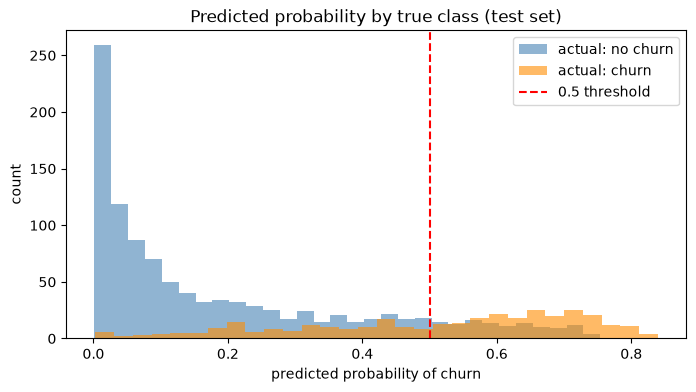

In [30]:
# Two histograms on the same axis, one per TRUE class:
#   blue   = predicted probability of customers who really did NOT churn
#   orange = predicted probability of customers who really DID churn
# A good model puts the two humps far apart; the overlap is where errors live.
plt.figure(figsize=(8, 4))
plt.hist(y_pred_test[y_test == 0], bins=30, alpha=0.6, label='actual: no churn', color='steelblue')
plt.hist(y_pred_test[y_test == 1], bins=30, alpha=0.6, label='actual: churn', color='darkorange')
# The 0.5 cutoff we used to turn probabilities into decisions
plt.axvline(0.5, color='red', linestyle='--', label='0.5 threshold')
plt.xlabel('predicted probability of churn')
plt.ylabel('count')
plt.title('Predicted probability by true class (test set)')
plt.legend()
plt.show()


To separate the classes further you'd need **more/better features** or a
**stronger model** (e.g. a tree-based one). That's the natural next step.


### Step 5: a dummy baseline — the sanity check every model needs

Before trusting any score, we ask: **how good is a model that learns nothing?** Fit a
`DummyClassifier` that always predicts the **most frequent class** ("no churn" for
almost everyone). Its accuracy equals the share of non-churners — and our real model
must clearly beat it to be worth anything.

**Why this matters:** on imbalanced data, accuracy can flatter a useless model. The
dummy sets the floor. If our model only ties the dummy, it has learned nothing useful.

**Package:** `sklearn.dummy.DummyClassifier`.


In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# DummyClassifier(strategy='most_frequent') always predicts the most common
# class in the training data - here "no churn". It learns nothing at all.
dummy = DummyClassifier(strategy='most_frequent').fit(df_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(df_test))

# The gap between the two is the value our real model actually adds.
print(f'dummy (always no churn) accuracy: {dummy_acc:.3f}')
print(f'our model            accuracy: {test_accuracy:.3f}')
print(f'improvement                  : {test_accuracy - dummy_acc:+.3f}')


dummy (always no churn) accuracy: 0.753
our model            accuracy: 0.812
improvement                  : +0.059


On this data the dummy scores ~0.75 (the non-churn rate) and our model ~0.81 — a
real but modest gain of about +0.06. Remember from Step 2 that about **41%** of churners
are still missed; the dummy reminds us accuracy alone doesn't tell that story.

### Step 6: the ROC curve — seeing every threshold at once

ROC-AUC collapsed the whole picture into one number. The **ROC curve** shows the
picture itself. We sweep the threshold from 0 to 1 and, at each point, plot:

- **x-axis = False Positive Rate (FPR)** = `FP / (FP + TN)` — fraction of non-churners
  we wrongly flagged.
- **y-axis = True Positive Rate (TPR)** = `TP / (TP + FN)` = **recall** — fraction of
  churners we caught.

So the curve traces the **recall vs false-alarm trade-off** across *all* thresholds.

- The **diagonal** (TPR = FPR) is the **random** model — a coin flip.
- The **top-left corner** (TPR = 1, FPR = 0) is the **ideal** model — catch everyone,
  flag no one by mistake.
- A good model bows toward the top-left; **AUC** is the area under the curve (0.5 for
  the diagonal, 1.0 for the ideal corner).

**Package:** `sklearn.metrics.roc_curve`.


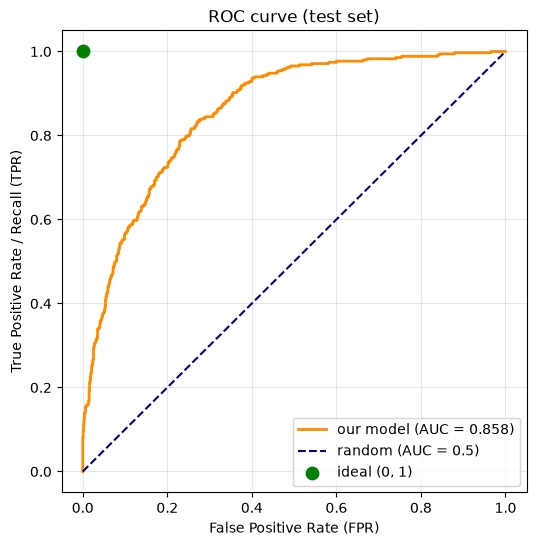

In [32]:
from sklearn.metrics import roc_curve

# Sweep the threshold from 0 to 1 and record, at each step:
#   fpr = share of non-churners wrongly flagged (false alarms)
#   tpr = share of churners correctly caught (= recall)
# thresholds is returned too but we don't need it for the plot.
fpr, tpr, thresholds = roc_curve(y_test, y_pred_test)
# AUC = the single number: area under this curve
auc = roc_auc_score(y_test, y_pred_test)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'our model (AUC = {auc:.3f})')
# The diagonal y = x is a model that guesses at random
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='random (AUC = 0.5)')
# The perfect model: catches everything (TPR=1), flags nothing wrongly (FPR=0)
plt.scatter([0], [1], color='green', s=80, zorder=5, label='ideal (0, 1)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate / Recall (TPR)')
plt.title('ROC curve (test set)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


Read it like this: pick a point on the curve = pick a threshold. Moving up-left
catches more churners but raises false alarms. The curve being well above the diagonal
(AUC ≈ 0.86) says the model **ranks** churners above non-churners far better than
chance — even though a single 0.5 cutoff (Step 3) doesn't nail the trade-off.


## 3.14 Cross-validation: a more reliable way to measure quality

Every number so far came from **one** train/validation/test split. That's fine, but
the result depends partly on **luck of the split** — re-split and the accuracy can
move by a point or two. If you're comparing models or tuning settings, one split can
mislead you.

**Cross-validation (k-fold)** fixes this:

1. Split the data into **k equal folds** (we use k = 5).
2. Train on k-1 folds, evaluate on the held-out fold. Repeat so **each fold is the
   test set once**.
3. You get **k scores**. Report their **mean** (the estimate) and **std** (how stable
   it is).

- **`StratifiedKFold`** keeps the class ratio in every fold — important for imbalanced
  data like this, so no fold ends up nearly all one class.
- **`cross_val_score`** runs the whole loop for you (it refits the pipeline, including
  preprocessing, on each fold — no leakage).

**Why it's more reliable:** averaging over k splits removes most of the split-luck, so
the number is closer to the truth. And it's how we **tune parameters** (next).

> We run CV on **train + validation** (`df_full_train`) — CV gives its own internal
> validation, so the test set still stays untouched for the final check.

**Packages:** `sklearn.model_selection` (`StratifiedKFold`, `cross_val_score`).


In [33]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 5 stratified folds, shuffled (random_state makes it reproducible).
# 'stratified' = every fold keeps the same churn/non-churn ratio.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# Features + target for CV: train + validation (the test set stays untouched)
X_all = df_full_train[categorical + numerical]
y_all = df_full_train[TARGET].values

# cross_val_score fits the whole pipeline once per fold and scores the
# held-out fold -> we get 5 numbers, one per fold.
cv_auc = cross_val_score(model_full, X_all, y_all, cv=cv, scoring='roc_auc')
print('AUC per fold:', [round(s, 3) for s in cv_auc])
# mean = our best estimate of quality; std = how much the score moves between folds
print(f'mean AUC: {cv_auc.mean():.3f}  (+/- {cv_auc.std():.3f})')


AUC per fold: [np.float64(0.841), np.float64(0.843), np.float64(0.85), np.float64(0.836), np.float64(0.84)]
mean AUC: 0.842  (+/- 0.005)


In [34]:
# Same loop, but scoring plain accuracy, to compare with the single-split number
cv_acc = cross_val_score(model_full, X_all, y_all, cv=cv, scoring='accuracy')
print('accuracy per fold:', [round(s, 3) for s in cv_acc])
print(f'mean accuracy: {cv_acc.mean():.3f}  (+/- {cv_acc.std():.3f})')


accuracy per fold: [np.float64(0.801), np.float64(0.8), np.float64(0.8), np.float64(0.805), np.float64(0.798)]
mean accuracy: 0.801  (+/- 0.002)


The folds cluster tightly (mean AUC ≈ 0.84 ± 0.005), which tells us the model's
quality is **stable** — the single-split test AUC of 0.86 was a fair, not lucky,
estimate.

### Tuning parameters with cross-validation

Now the payoff: **choosing hyperparameters**. Logistic regression has a
regularization strength `C` (small `C` = more regularization, large `C` = less). Rather
than guess, we try several values and let **`GridSearchCV`** run k-fold CV for each,
then keep the best by mean CV score — using a **CV score**, never the test set.

**Package:** `sklearn.model_selection.GridSearchCV`.



In [35]:
from sklearn.model_selection import GridSearchCV

# Try each C value and score it with the same 5-fold CV used above.
# NOTE: in a Pipeline you must prefix the parameter with the step name,
# so the model's C is addressed as 'model__C' (step name + '__' + param).
param_grid = {'model__C': [0.001, 0.01, 0.1, 1, 10]}

# GridSearchCV = "try every combination, keep the one with the best mean CV score".
# n_jobs=-1 = use all CPU cores (faster).
grid = GridSearchCV(model_full, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_all, y_all)

print('best C      :', grid.best_params_['model__C'])
print('best CV AUC :', round(grid.best_score_, 3))


best C      : 1
best CV AUC : 0.842


`GridSearchCV` also stores every setting's score in `grid.cv_results_`, so you can see
the full curve of AUC vs `C`. Here the model is fairly insensitive — the best `C`
yields about the same CV AUC — which is a useful finding: tuning `C` won't rescue
this model. Real gains would come from **better features** or a **stronger model**
(see Next steps), not from fiddling with `C`.


## 3.15 Summary

**The workflow (memorize this):**

1. **Load & clean** — consistent names, numeric columns are numbers, target is 0/1.
2. **Split** — train / validation / test (60/20/20).
3. **Explore** — profile the data; rank features by importance.
4. **Preprocess** — one-hot encode categoricals + scale numerics, inside a
   `ColumnTransformer`.
5. **Train** — fit `LogisticRegression` in a `Pipeline`.
6. **Interpret** — read the coefficients.
7. **Refit & test** — train on train+val, evaluate once on the test set.
8. **Analyze errors** — confusion matrix, precision/recall/F1, ROC curve & AUC, threshold.
9. **Validate robustly** — compare to a dummy baseline; confirm with k-fold cross-validation.

**Key concepts**
- **Feature importance** — risk ratio / mutual information / correlation.
- **One-hot encoding** — categories → 0/1 columns.
- **Logistic regression** — a linear model + sigmoid → a probability.
- **Imbalanced data** — accuracy misleads; use precision/recall/F1 and ROC-AUC, and
  always sanity-check against a **dummy** (majority-class) baseline.
- **ROC curve vs AUC** — the curve shows the recall/false-alarm trade-off across
  thresholds; AUC is its single-number summary.
- **Cross-validation** — k-fold averages over split-luck for a more reliable score, and
  is how hyperparameters get tuned (e.g. `GridSearchCV`).

**Reusing the template:** change only the knobs — `DATA_PATH`, `TARGET`,
`POSITIVE_LABEL`, `numerical`, `categorical`. Everything else stays the same.

## 3.16 Next steps

- Drop weak features (low mutual information, weights near 0) and re-check.
- Tune the decision threshold for the business cost (3.13).
- Try a tree-based model (`RandomForestClassifier`, `GradientBoostingClassifier`)
  and compare ROC-AUC.

More practice datasets:

* Lead scoring - <https://www.kaggle.com/ashydv/leads-dataset>
* Default prediction - <https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients>

